# Yachida CRC — PCA, UMAP, and Volcano Plots

Loads and preprocesses all three data blocks directly from the public Yachida source.

    Healthy_vs_Stage_0
    Healthy_vs_Stage_I_II
    Healthy_vs_Stage_III_IV
    Healthy_vs_Early_CRC(Stage_0 + Stage_I_II)
    Healthy_vs_Invasive_CRC(Stage_I_II + Stage_III_IV)

## 1. setup

In [1]:
from pathlib import Path
import importlib.util
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import warnings
import zipfile

try:
    from IPython.display import display
except Exception:
    display = print

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except Exception:
    colab_files = None
    IN_COLAB = False

PROJECT_ROOT = Path(
    os.environ.get("YACHIDA_PROJECT_ROOT", "/content" if IN_COLAB else Path.cwd())
).expanduser().resolve()
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)


def ensure_optional_package(module_name, pip_name=None):

    if importlib.util.find_spec(module_name) is not None:
        return True
    if not IN_COLAB:
        return False
    pip_name = pip_name or module_name
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
    except Exception as exc:
        print(f"[WARNING] Could not install optional package {pip_name!r}: {exc}")
        return False
    return importlib.util.find_spec(module_name) is not None

FAST_MODE = os.environ.get("YACHIDA_FAST_TEST", "0") == "1"

warnings.filterwarnings("ignore")
print(f"Runtime: {'Google Colab' if IN_COLAB else 'local Jupyter/Python'}")
print(f"Project root: {PROJECT_ROOT}")

Runtime: Google Colab
Project root: /content


In [2]:
# Core imports
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGET_PAIRED_N = 347
PREVALENCE_THRESHOLD = 0.05
MIN_MEAN_REL_ABUNDANCE = 1e-6
TAXA_PSEUDOCOUNT = 1e-6
METABOLITE_PSEUDOCOUNT = 1.0
FDR_THRESHOLD = 0.05
LOG2FC_THRESHOLD = 0.5

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)


OUT_DIR = PROJECT_ROOT / "03_Yachida_PCA_UMAP_Volcano_results"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
for directory in [OUT_DIR, FIG_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUT_DIR}")

Output directory: /content/03_Yachida_PCA_UMAP_Volcano_results


## 2. Independent data loading and preprocessing

In [3]:
# Download, load, match, and preprocess the Yachida data independently.
REPO_URL = "https://github.com/borenstein-lab/microbiome-metabolome-curated-data.git"
REPO_NAME = "microbiome-metabolome-curated-data"
REPO_DIR = PROJECT_ROOT / REPO_NAME
DEFAULT_DATA_DIR = REPO_DIR / "data" / "processed_data" / "YACHIDA_CRC_2019"


def _download_repository_with_zip(destination):
    "
    for branch in ("master", "main"):
        url = f"https://github.com/borenstein-lab/{REPO_NAME}/archive/refs/heads/{branch}.zip"
        archive = PROJECT_ROOT / f"{REPO_NAME}-{branch}.zip"
        extracted = PROJECT_ROOT / f"{REPO_NAME}-{branch}"
        try:
            print(f"[INFO] Downloading repository ZIP from {url}")
            urllib.request.urlretrieve(url, archive)
            with zipfile.ZipFile(archive) as zf:
                zf.extractall(PROJECT_ROOT)
            if destination.exists():
                shutil.rmtree(destination)
            extracted.rename(destination)
            archive.unlink(missing_ok=True)
            return
        except Exception as exc:
            print(f"[WARNING] ZIP download for branch {branch!r} failed: {exc}")
            archive.unlink(missing_ok=True)
            if extracted.exists():
                shutil.rmtree(extracted)
    raise RuntimeError(
        "The public Yachida repository could not be downloaded. "
        "Check the runtime's internet connection, or set environment variable "
        "YACHIDA_DATA_DIR to a local YACHIDA_CRC_2019 folder."
    )


def resolve_data_dir():
    override = os.environ.get("YACHIDA_DATA_DIR")
    if override:
        data_dir = Path(override).expanduser().resolve()
        if not data_dir.exists():
            raise FileNotFoundError(f"YACHIDA_DATA_DIR does not exist: {data_dir}")
        print(f"[INFO] Using data directory from YACHIDA_DATA_DIR: {data_dir}")
        return data_dir

    if DEFAULT_DATA_DIR.exists():
        print(f"[INFO] Using existing repository data: {DEFAULT_DATA_DIR}")
        return DEFAULT_DATA_DIR

    if REPO_DIR.exists() and not DEFAULT_DATA_DIR.exists():
        print(f"[WARNING] Removing incomplete repository folder: {REPO_DIR}")
        shutil.rmtree(REPO_DIR)

    git_executable = shutil.which("git")
    if git_executable:
        try:
            print(f"[INFO] Cloning public repository into {REPO_DIR}")
            subprocess.run(
                [git_executable, "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
                cwd=PROJECT_ROOT,
                check=True,
            )
        except Exception as exc:
            print(f"[WARNING] git clone failed: {exc}")

    if not DEFAULT_DATA_DIR.exists():
        _download_repository_with_zip(REPO_DIR)

    if not DEFAULT_DATA_DIR.exists():
        raise FileNotFoundError(f"Dataset directory was not found after download: {DEFAULT_DATA_DIR}")
    return DEFAULT_DATA_DIR


DATA_DIR = resolve_data_dir()


def _clean_labels(values):
    return pd.Index([str(value).strip() for value in values])


def read_metadata(path):
    raw = pd.read_csv(path, sep="\t", low_memory=False)
    if raw.empty:
        raise ValueError(f"Metadata file is empty: {path}")

    normalized = {re.sub(r"[^a-z0-9]", "", str(col).lower()): col for col in raw.columns}
    sample_candidates = ["sample", "sampleid", "sampleidentifier", "id"]
    sample_col = next((normalized[key] for key in sample_candidates if key in normalized), None)

    if sample_col is None:
        # The curated Yachida metadata historically stores sample IDs in the second column.
        sample_col = raw.columns[1] if raw.shape[1] >= 2 else raw.columns[0]
        print(f"[WARNING] No standard sample-ID column name found; using {sample_col!r}.")

    raw[sample_col] = raw[sample_col].astype(str).str.strip()
    meta = raw.drop_duplicates(subset=[sample_col], keep="first").set_index(sample_col)
    meta.index.name = "Sample_ID"

    normalized_meta = {re.sub(r"[^a-z0-9]", "", str(col).lower()): col for col in meta.columns}
    group_candidates = ["studygroup", "group", "diseasegroup", "condition", "diagnosis"]
    group_col = next((normalized_meta[key] for key in group_candidates if key in normalized_meta), None)
    if group_col is None:
        raise KeyError(
            "No clinical group column was found. Expected a column such as "
            "'Study.Group', 'Group', 'Condition', or 'Diagnosis'."
        )
    return meta, group_col


def canonicalize_group(value):
    if pd.isna(value):
        return np.nan
    text = re.sub(r"[^a-z0-9]+", "", str(value).strip().lower())
    if text in {"healthy", "control", "controls", "normal", "hc"}:
        return "Healthy"
    if text in {"stage0", "s0", "crcstage0"}:
        return "Stage_0"
    if text in {"stageiii", "stage12", "siii", "s12", "stage1and2", "stageiandii"}:
        return "Stage_I_II"
    if text in {"stageiiiiv", "stage34", "siiiiv", "s34", "stage3and4", "stageiiiandiv"}:
        return "Stage_III_IV"
    return str(value).strip()


def read_feature_table(path, metadata_ids, duplicate_policy="sum"):
    frame = pd.read_csv(path, sep="\t", index_col=0, compression="infer", low_memory=False)
    frame.index = _clean_labels(frame.index)
    frame.columns = _clean_labels(frame.columns)
    metadata_ids = set(map(str, metadata_ids))

    index_overlap = len(set(frame.index) & metadata_ids)
    column_overlap = len(set(frame.columns) & metadata_ids)
    if column_overlap > index_overlap:
        frame = frame.T
        frame.index = _clean_labels(frame.index)
        frame.columns = _clean_labels(frame.columns)
        index_overlap = column_overlap

    if index_overlap == 0:
        raise ValueError(
            f"No sample IDs in {path.name} overlap the metadata. "
            "The table orientation or sample-ID format is not recognized."
        )

    frame = frame.loc[~frame.index.duplicated(keep="first")]
    if frame.columns.duplicated().any():
        grouped = frame.T.groupby(level=0)
        frame = grouped.mean().T if duplicate_policy == "mean" else grouped.sum().T
    return frame.apply(pd.to_numeric, errors="coerce")


def first_existing(*paths):
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError("None of the required alternatives exists: " + ", ".join(map(str, paths)))


required_core = [DATA_DIR / "metadata.tsv", DATA_DIR / "mtb.tsv"]
missing_core = [path.name for path in required_core if not path.exists()]
if missing_core:
    raise FileNotFoundError(f"Missing required Yachida files: {missing_core} in {DATA_DIR}")

metadata_raw, ORIGINAL_GROUP_COL = read_metadata(DATA_DIR / "metadata.tsv")
metadata_raw["Group_Original"] = metadata_raw[ORIGINAL_GROUP_COL].astype(str)
metadata_raw["Group_Canonical"] = metadata_raw[ORIGINAL_GROUP_COL].map(canonicalize_group)
GROUP_COL = "Group_Canonical"
metadata_ids = set(metadata_raw.index.astype(str))

species_path = first_existing(DATA_DIR / "species.counts.tsv", DATA_DIR / "species.tsv.zip")
genera_path = first_existing(DATA_DIR / "genera.counts.tsv", DATA_DIR / "genera.tsv")
metabolomics_path = DATA_DIR / "mtb.tsv"

species_raw = read_feature_table(species_path, metadata_ids, duplicate_policy="sum")
genera_raw = read_feature_table(genera_path, metadata_ids, duplicate_policy="sum")
metabolomics_raw = read_feature_table(metabolomics_path, metadata_ids, duplicate_policy="mean")

sample_sets = {
    "metadata": set(metadata_raw.index),
    "species": set(species_raw.index),
    "genera": set(genera_raw.index),
    "metabolomics": set(metabolomics_raw.index),
}
paired_ids = sorted(set.intersection(*sample_sets.values()))
if not paired_ids:
    raise ValueError("No samples are shared across metadata, species, genera, and metabolomics.")

metadata = metadata_raw.loc[paired_ids].copy()
species_counts = species_raw.loc[paired_ids].copy()
genera_counts = genera_raw.loc[paired_ids].copy()
metabolomics = metabolomics_raw.loc[paired_ids].copy()

if len(paired_ids) != TARGET_PAIRED_N:
    print(f"[WARNING] Expected {TARGET_PAIRED_N} paired samples from the published curated set; found {len(paired_ids)}.")
else:
    print(f"[OK] Found the expected {TARGET_PAIRED_N} paired samples.")

sample_audit = pd.DataFrame({
    "Layer": list(sample_sets),
    "Samples_Loaded": [len(sample_sets[name]) for name in sample_sets],
    "Samples_In_Paired_Cohort": len(paired_ids),
})
sample_audit.to_csv(TABLE_DIR / "sample_id_audit_summary.csv", index=False)

master_mapping = metadata[["Group_Original", GROUP_COL]].copy()
master_mapping.insert(0, "Sample_ID", master_mapping.index)
master_mapping.to_csv(TABLE_DIR / "master_sample_mapping.csv", index=False)


def preprocess_taxonomy(counts):
    numeric = counts.apply(pd.to_numeric, errors="coerce").fillna(0.0).clip(lower=0.0)
    totals = numeric.sum(axis=1).replace(0.0, np.nan)
    relative = numeric.div(totals, axis=0).fillna(0.0)
    prevalence = (relative > 0).mean(axis=0)
    mean_abundance = relative.mean(axis=0)
    keep = (prevalence >= PREVALENCE_THRESHOLD) & (mean_abundance >= MIN_MEAN_REL_ABUNDANCE)
    if not keep.any():
        keep.loc[mean_abundance.nlargest(min(10, len(mean_abundance))).index] = True
    filtered = relative.loc[:, keep].copy()
    log_frame = np.log10(filtered + TAXA_PSEUDOCOUNT)
    scaled = pd.DataFrame(
        StandardScaler().fit_transform(log_frame),
        index=log_frame.index,
        columns=log_frame.columns,
    )
    return {"raw": numeric, "relative": relative, "filtered": filtered, "log": log_frame, "scaled": scaled}


def preprocess_metabolomics(frame):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    keep = numeric.notna().mean(axis=0).ge(0.20) & numeric.var(axis=0, skipna=True).fillna(0).gt(0)
    if not keep.any():
        keep.loc[numeric.notna().mean(axis=0).nlargest(min(10, numeric.shape[1])).index] = True
    filtered = numeric.loc[:, keep].copy()
    log_frame = np.log10(filtered.clip(lower=0.0) + METABOLITE_PSEUDOCOUNT)
    medians = log_frame.median(axis=0, skipna=True)
    imputed = log_frame.fillna(medians).fillna(0.0)
    scaled = pd.DataFrame(
        StandardScaler().fit_transform(imputed),
        index=imputed.index,
        columns=imputed.columns,
    )
    return {"raw": numeric, "filtered": filtered, "log": log_frame, "imputed": imputed, "scaled": scaled}


species_prep = preprocess_taxonomy(species_counts)
genera_prep = preprocess_taxonomy(genera_counts)
metabolomics_prep = preprocess_metabolomics(metabolomics)

data_blocks = {
    "species": species_prep["scaled"],
    "genera": genera_prep["scaled"],
    "metabolomics": metabolomics_prep["scaled"],
}
differential_blocks = {
    "species": species_prep["filtered"],
    "genera": genera_prep["filtered"],
    "metabolomics": metabolomics_prep["filtered"],
}
ml_blocks = {
    "species": species_prep["log"].add_prefix("species|"),
    "genera": genera_prep["log"].add_prefix("genera|"),
    "metabolomics": metabolomics_prep["imputed"].add_prefix("metabolite|"),
}
ml_blocks["species_plus_metabolomics"] = pd.concat([ml_blocks["species"], ml_blocks["metabolomics"]], axis=1)
ml_blocks["genera_plus_metabolomics"] = pd.concat([ml_blocks["genera"], ml_blocks["metabolomics"]], axis=1)

for name, frame in data_blocks.items():
    frame.to_csv(TABLE_DIR / f"{name}_preprocessed_scaled.csv")

print("Clinical groups in the paired cohort:")
display(metadata[GROUP_COL].value_counts().rename_axis("Group").to_frame("N"))
print("Preprocessed feature counts:", {name: frame.shape[1] for name, frame in data_blocks.items()})

[INFO] Cloning public repository into /content/microbiome-metabolome-curated-data
[OK] Found the expected 347 paired samples.
Clinical groups in the paired cohort:


,N
Group,
Healthy,127
Stage_I_II,69
Stage_III_IV,54
MP,40
HS,30
Stage_0,27


Preprocessed feature counts: {'species': 6940, 'genera': 1870, 'metabolomics': 446}


## 3. Contrasts and helper functions

In [4]:
# Define robust contrasts and differential-testing helpers.
CONTRAST_CANDIDATES = {
    "Healthy_vs_Stage_0": (["Healthy"], ["Stage_0"]),
    "Healthy_vs_Stage_I_II": (["Healthy"], ["Stage_I_II"]),
    "Healthy_vs_Stage_III_IV": (["Healthy"], ["Stage_III_IV"]),
    "Healthy_vs_Early_CRC": (["Healthy"], ["Stage_0", "Stage_I_II"]),
    "Healthy_vs_Invasive_CRC": (["Healthy"], ["Stage_I_II", "Stage_III_IV"]),
}
available_groups = set(metadata[GROUP_COL].dropna().astype(str).unique())
ACTIVE_CONTRASTS = {
    name: {"Group_A_Labels": group_a, "Group_B_Labels": group_b}
    for name, (group_a, group_b) in CONTRAST_CANDIDATES.items()
    if set(group_a + group_b).issubset(available_groups)
}
if not ACTIVE_CONTRASTS:
    raise ValueError(f"No expected Healthy-versus-CRC contrasts are available. Labels: {sorted(available_groups)}")

contrast_rows = []
for name, spec in ACTIVE_CONTRASTS.items():
    contrast_rows.append({
        "Contrast": name,
        "Group_A": "+".join(spec["Group_A_Labels"]),
        "Group_B": "+".join(spec["Group_B_Labels"]),
        "N_Group_A": int(metadata[GROUP_COL].isin(spec["Group_A_Labels"]).sum()),
        "N_Group_B": int(metadata[GROUP_COL].isin(spec["Group_B_Labels"]).sum()),
    })
contrast_table = pd.DataFrame(contrast_rows)
contrast_table.to_csv(TABLE_DIR / "active_contrasts.csv", index=False)
display(contrast_table)


def get_contrast_data(frame, contrast_name):
    spec = ACTIVE_CONTRASTS[contrast_name]
    labels_a = spec["Group_A_Labels"]
    labels_b = spec["Group_B_Labels"]
    ids = metadata.index[metadata[GROUP_COL].isin(labels_a + labels_b)]
    X = frame.loc[ids].copy()
    y = metadata.loc[ids, GROUP_COL].isin(labels_b).astype(int)
    return X, y


def run_differential(frame, group_a_ids, group_b_ids, is_microbiome):
    pseudo = TAXA_PSEUDOCOUNT if is_microbiome else METABOLITE_PSEUDOCOUNT
    records = []
    for feature in frame.columns:
        values_a = pd.to_numeric(frame.loc[group_a_ids, feature], errors="coerce").dropna()
        values_b = pd.to_numeric(frame.loc[group_b_ids, feature], errors="coerce").dropna()
        if values_a.empty or values_b.empty:
            statistic, p_value = np.nan, 1.0
        else:
            try:
                statistic, p_value = mannwhitneyu(values_a, values_b, alternative="two-sided")
            except Exception:
                statistic, p_value = np.nan, 1.0
        mean_a = float(values_a.mean()) if not values_a.empty else np.nan
        mean_b = float(values_b.mean()) if not values_b.empty else np.nan
        fold_change = np.log2((mean_b + pseudo) / (mean_a + pseudo)) if np.isfinite(mean_a) and np.isfinite(mean_b) else np.nan
        records.append({
            "Feature": feature,
            "Mean_Group_A": mean_a,
            "Mean_Group_B": mean_b,
            "Log2FC_GroupB_vs_GroupA": fold_change,
            "MannWhitneyU": statistic,
            "P_Value": p_value,
        })
    result = pd.DataFrame(records)
    if result.empty:
        return pd.DataFrame(columns=[
            "Feature", "Mean_Group_A", "Mean_Group_B", "Log2FC_GroupB_vs_GroupA",
            "MannWhitneyU", "P_Value", "FDR_BH", "Significant_FDR"
        ])
    result["FDR_BH"] = multipletests(result["P_Value"].fillna(1.0), method="fdr_bh")[1]
    result["Significant_FDR"] = result["FDR_BH"] < FDR_THRESHOLD
    return result.sort_values(["FDR_BH", "P_Value"], kind="stable").reset_index(drop=True)


def draw_volcano(result, title, ax):
    if result.empty:
        ax.text(0.5, 0.5, "No features available", ha="center", va="center")
        ax.set_title(title)
        return
    plot_data = result.copy()
    plot_data["NegLog10FDR"] = -np.log10(plot_data["FDR_BH"].clip(lower=1e-300))
    plot_data["Status"] = "Not significant"
    plot_data.loc[
        (plot_data["FDR_BH"] < FDR_THRESHOLD) &
        (plot_data["Log2FC_GroupB_vs_GroupA"] >= LOG2FC_THRESHOLD),
        "Status",
    ] = "Higher in disease"
    plot_data.loc[
        (plot_data["FDR_BH"] < FDR_THRESHOLD) &
        (plot_data["Log2FC_GroupB_vs_GroupA"] <= -LOG2FC_THRESHOLD),
        "Status",
    ] = "Lower in disease"
    for status_name, status_frame in plot_data.groupby("Status", sort=True):
        ax.scatter(
            status_frame["Log2FC_GroupB_vs_GroupA"],
            status_frame["NegLog10FDR"],
            s=20,
            alpha=0.7,
            label=str(status_name),
        )
    ax.axhline(-np.log10(FDR_THRESHOLD), linestyle="--", linewidth=1)
    ax.axvline(LOG2FC_THRESHOLD, linestyle="--", linewidth=1)
    ax.axvline(-LOG2FC_THRESHOLD, linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="log2 fold change", ylabel="-log10(FDR)")
    ax.legend(fontsize=7, title=None)

,Contrast,Group_A,Group_B,N_Group_A,N_Group_B
0,Healthy_vs_Stage_0,Healthy,Stage_0,127,27
1,Healthy_vs_Stage_I_II,Healthy,Stage_I_II,127,69
2,Healthy_vs_Stage_III_IV,Healthy,Stage_III_IV,127,54
3,Healthy_vs_Early_CRC,Healthy,Stage_0+Stage_I_II,127,96
4,Healthy_vs_Invasive_CRC,Healthy,Stage_I_II+Stage_III_IV,127,123


## 4. PCA and UMAP

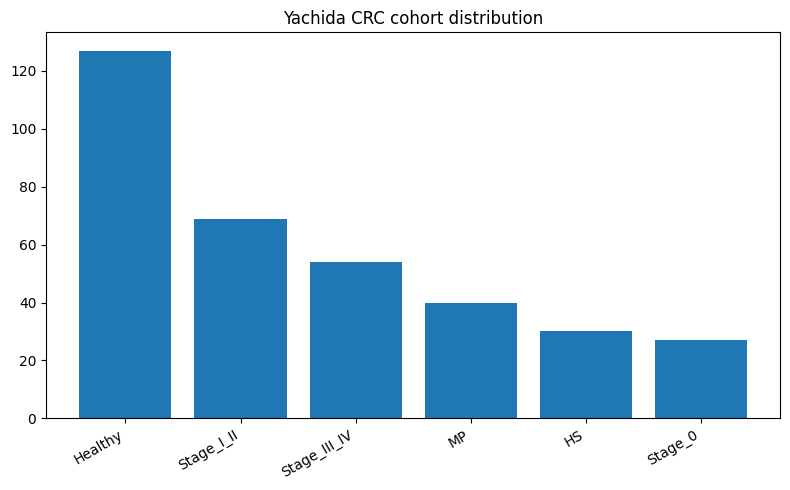

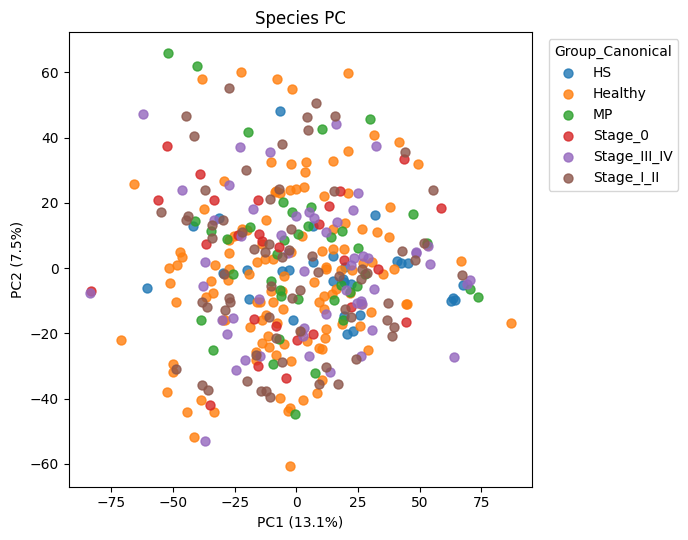

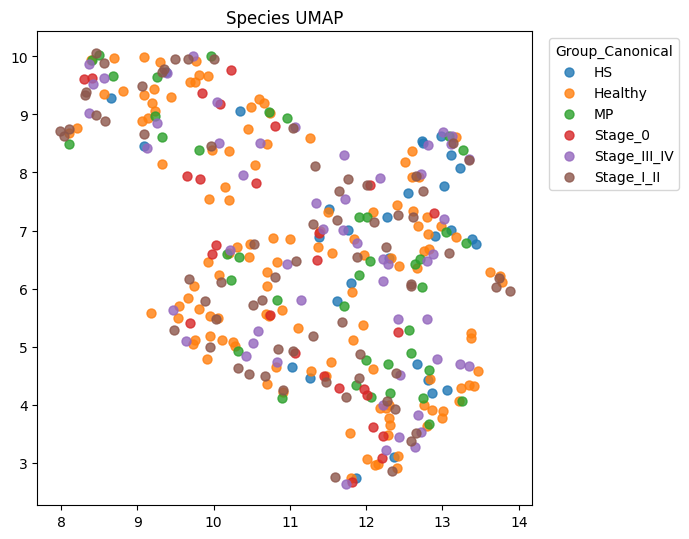

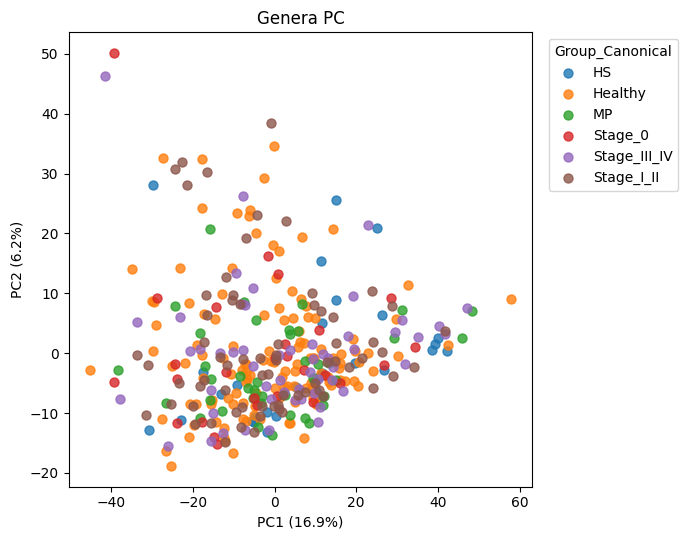

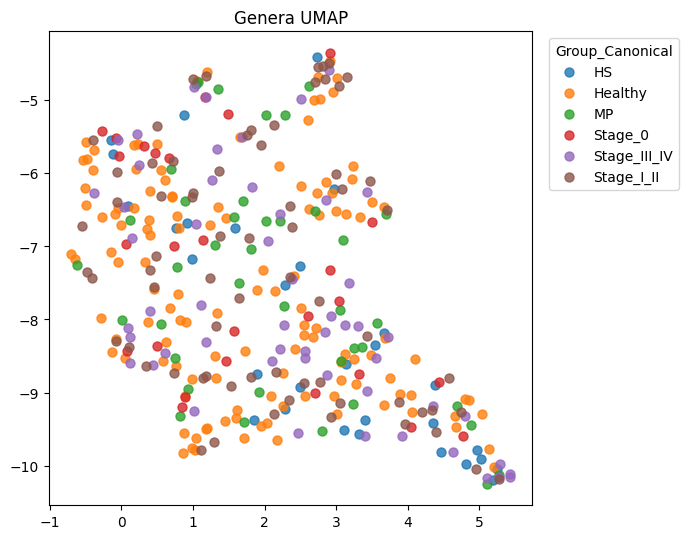

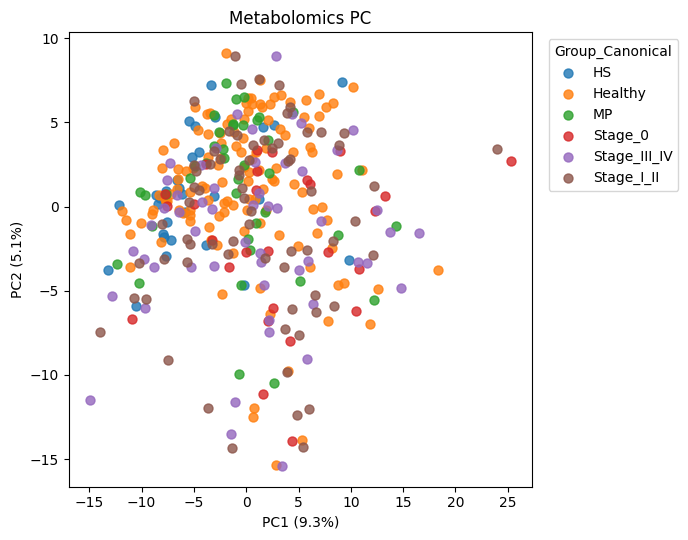

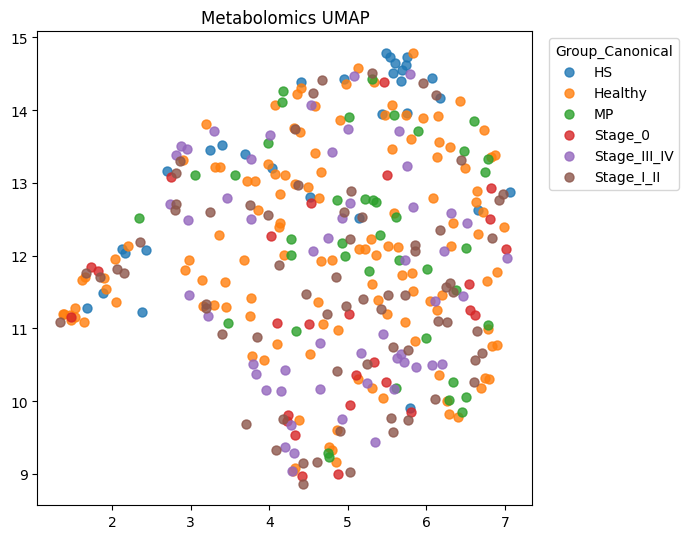

In [5]:
# Cohort distribution, PCA, and UMAP (with a PCA fallback if umap-learn is unavailable).
HAS_UMAP = ensure_optional_package("umap", "umap-learn")
if HAS_UMAP:
    import umap
else:
    umap = None
    print("[WARNING] umap-learn is unavailable; a PCA-based 2D fallback will be used for UMAP outputs.")

stage_counts = metadata[GROUP_COL].value_counts().rename_axis("Study_Group").reset_index(name="N")
stage_counts["Percent"] = 100 * stage_counts["N"] / stage_counts["N"].sum()
stage_counts.to_csv(TABLE_DIR / "disease_stage_distribution.csv", index=False)

plt.figure(figsize=(8, 5))
plt.bar(stage_counts["Study_Group"].astype(str), stage_counts["N"].astype(float))
plt.title("Yachida CRC cohort distribution")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "disease_stage_distribution_counts.png", dpi=250, bbox_inches="tight")
plt.show()
plt.close()


def ensure_two_columns(values):
    values = np.asarray(values)
    if values.ndim == 1:
        values = values[:, None]
    if values.shape[1] == 1:
        values = np.column_stack([values[:, 0], np.zeros(values.shape[0])])
    return values[:, :2]


def plot_embedding(coords, block_name, method, variance=None):
    coords = ensure_two_columns(coords)
    frame = pd.DataFrame(coords, index=metadata.index, columns=[f"{method}1", f"{method}2"])
    frame[GROUP_COL] = metadata[GROUP_COL].astype(str)
    frame.to_csv(TABLE_DIR / f"{block_name}_{method.lower()}_coordinates.csv")

    plt.figure(figsize=(7, 5.5))
    for group_name, group_frame in frame.groupby(GROUP_COL, sort=True):
        plt.scatter(group_frame[f"{method}1"], group_frame[f"{method}2"], s=42, alpha=0.8, label=str(group_name))
    if variance is not None and len(variance) >= 2:
        plt.xlabel(f"PC1 ({variance[0]:.1%})")
        plt.ylabel(f"PC2 ({variance[1]:.1%})")
    plt.title(f"{block_name.title()} {method}")
    plt.legend(title=GROUP_COL, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{block_name}_{method.lower()}.png", dpi=250, bbox_inches="tight")
    plt.show()
    plt.close()


embedding_status = []
for block_name, frame in data_blocks.items():
    max_components = max(1, min(2, frame.shape[0], frame.shape[1]))
    pca = PCA(n_components=max_components, random_state=RANDOM_STATE)
    pca_coords = pca.fit_transform(frame)
    plot_embedding(pca_coords, block_name, "PC", pca.explained_variance_ratio_)

    if HAS_UMAP and frame.shape[0] >= 4:
        n_neighbors = min(15, max(2, frame.shape[0] - 1))
        reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors, random_state=RANDOM_STATE)
        umap_coords = reducer.fit_transform(frame)
        method_used = "UMAP"
    else:
        fallback = PCA(n_components=max_components, random_state=RANDOM_STATE)
        umap_coords = fallback.fit_transform(frame)
        method_used = "PCA fallback"
    plot_embedding(umap_coords, block_name, "UMAP")
    embedding_status.append({"Block": block_name, "UMAP_Output_Method": method_used})

pd.DataFrame(embedding_status).to_csv(TABLE_DIR / "embedding_method_status.csv", index=False)

## 5. Differential testing and volcano plots

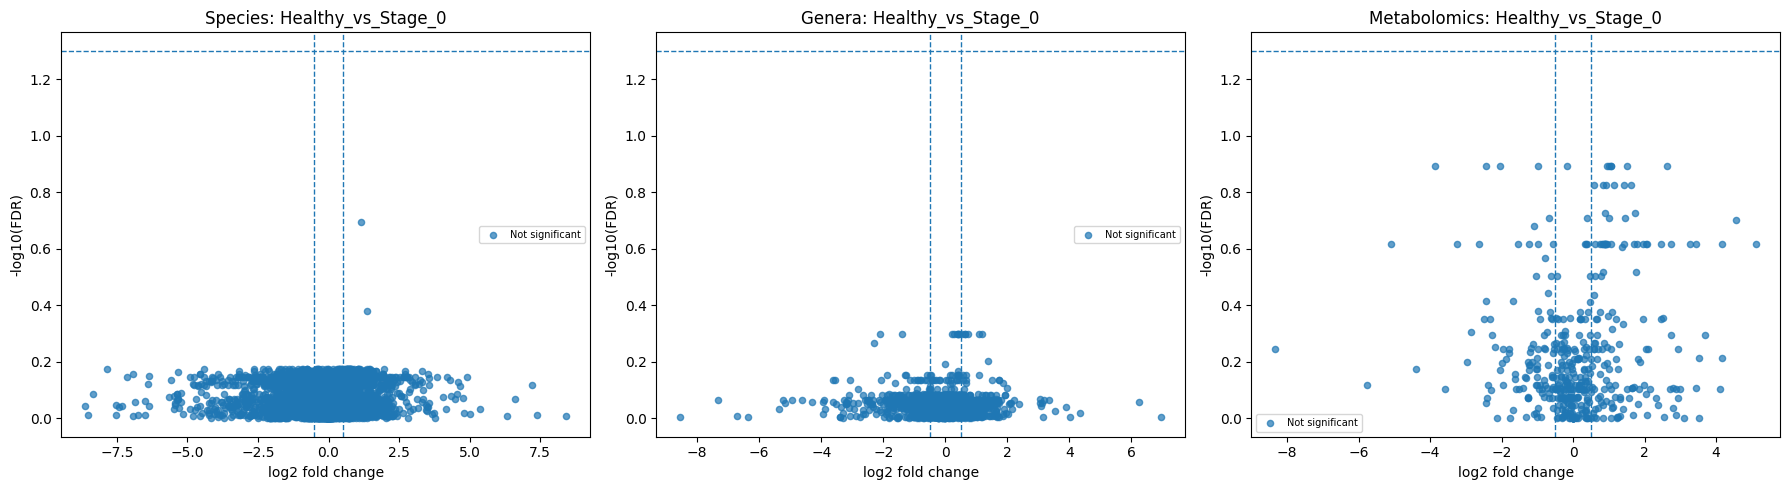

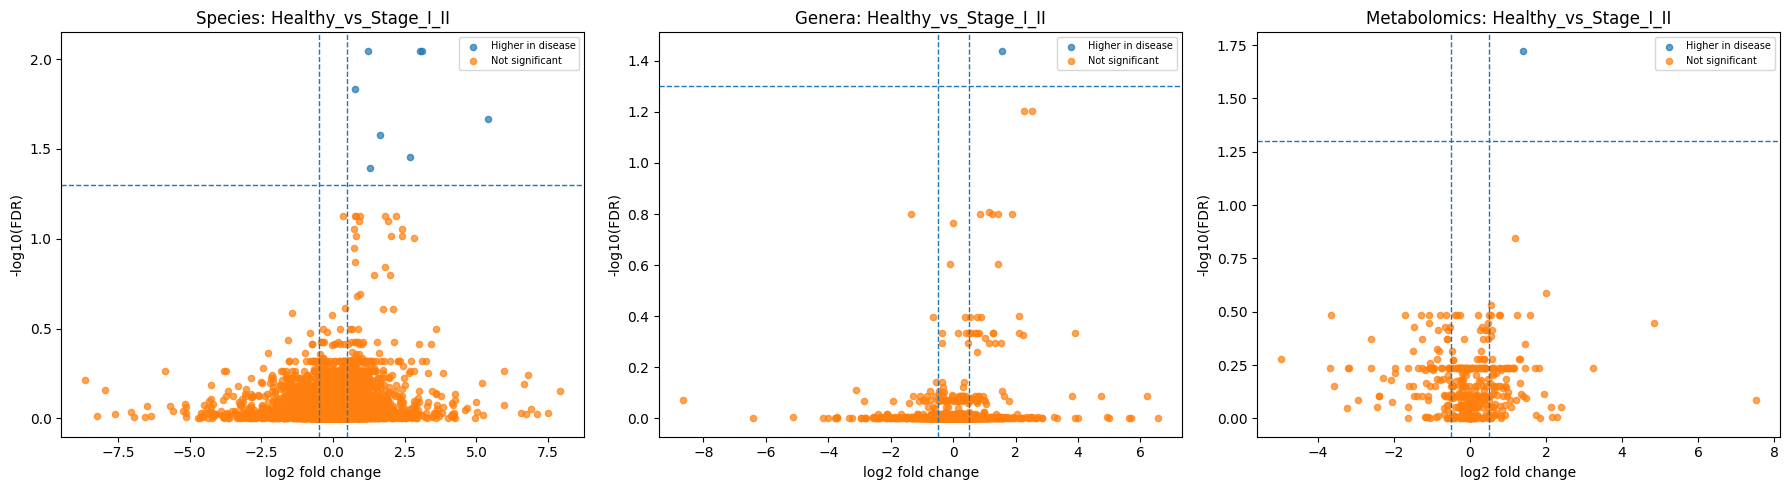

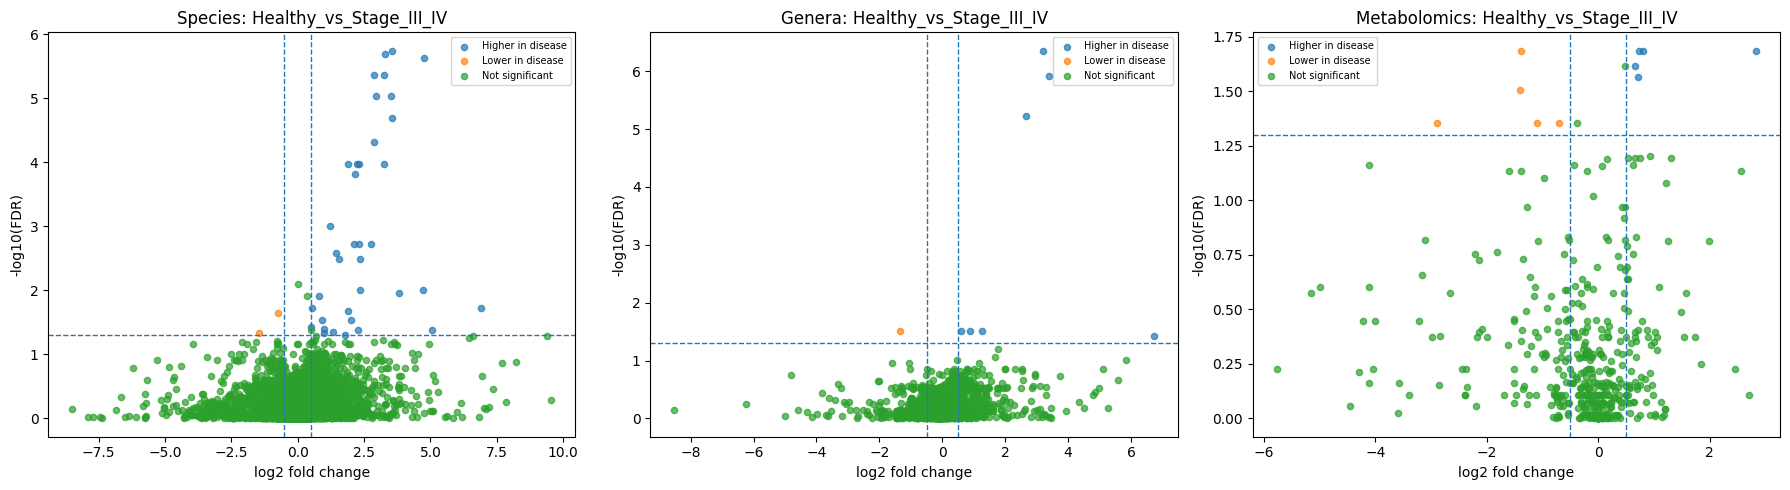

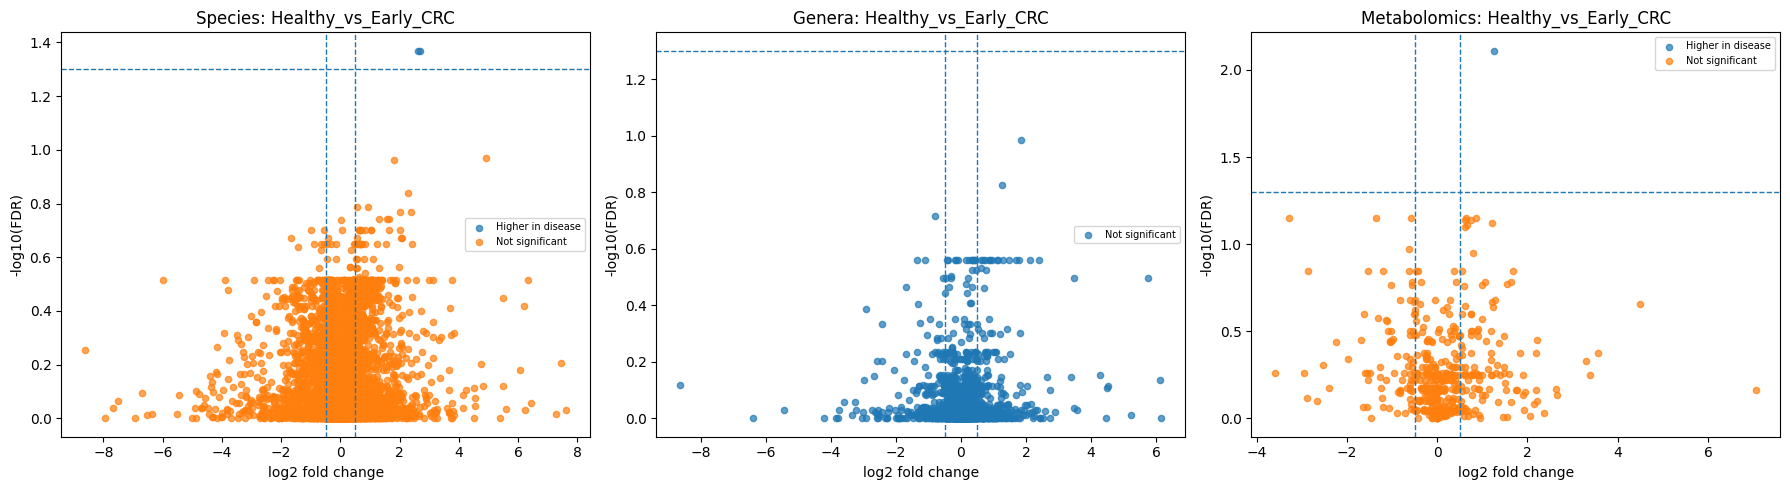

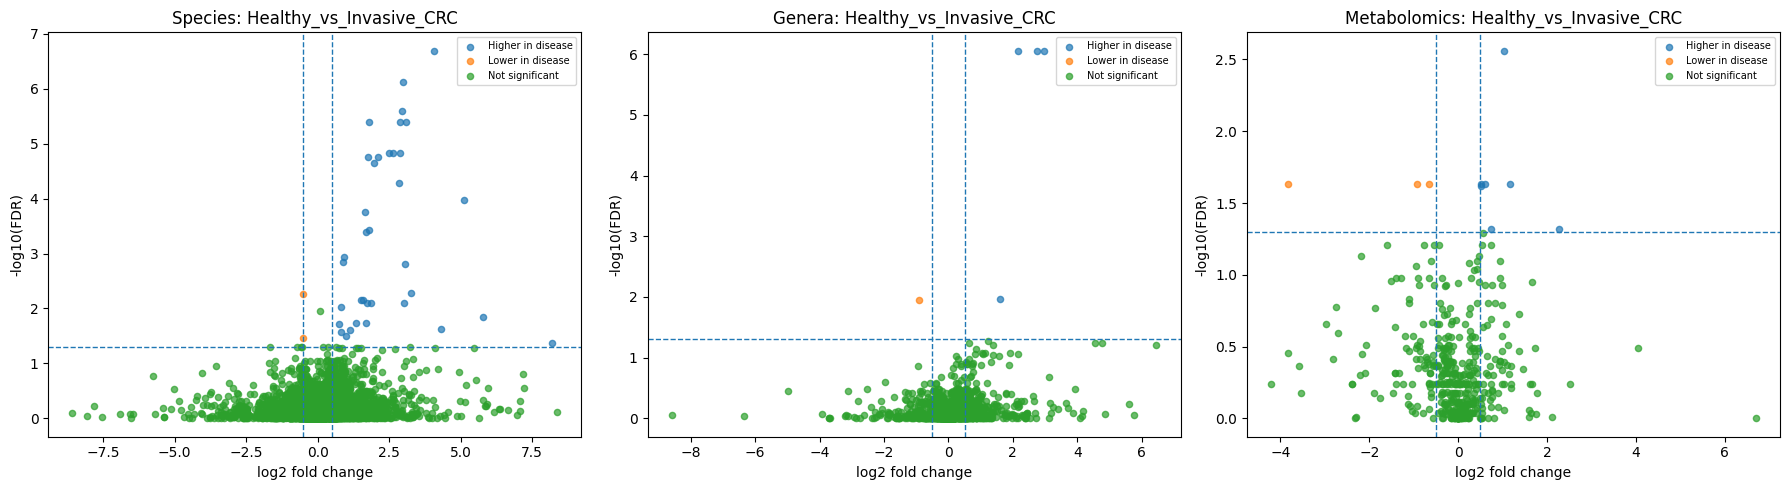

Completed differential testing for 5 independent contrasts.


In [6]:
# Run differential testing and save volcano plots.
diff_results = {}
diff_summary = []
for contrast_name, spec in ACTIVE_CONTRASTS.items():
    group_a_ids = metadata.index[metadata[GROUP_COL].isin(spec["Group_A_Labels"])]
    group_b_ids = metadata.index[metadata[GROUP_COL].isin(spec["Group_B_Labels"])]

    for block_name, frame in differential_blocks.items():
        result = run_differential(
            frame,
            group_a_ids,
            group_b_ids,
            is_microbiome=block_name in {"species", "genera"},
        )
        diff_results[(block_name, contrast_name)] = result
        result.to_csv(TABLE_DIR / f"{block_name}_differential_{contrast_name}.csv", index=False)
        diff_summary.append({
            "Contrast": contrast_name,
            "Dataset": block_name,
            "N_Group_A": len(group_a_ids),
            "N_Group_B": len(group_b_ids),
            "Features_Tested": len(result),
            "Significant_FDR": int(result["Significant_FDR"].sum()) if not result.empty else 0,
        })

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, block_name in zip(axes, ["species", "genera", "metabolomics"]):
        draw_volcano(diff_results[(block_name, contrast_name)], f"{block_name.title()}: {contrast_name}", ax)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"volcano_all_blocks_{contrast_name}.png", dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

pd.DataFrame(diff_summary).to_csv(TABLE_DIR / "differential_testing_summary_all_blocks.csv", index=False)
print(f"Completed differential testing for {len(ACTIVE_CONTRASTS)} independent contrasts.")

## 6. Package outputs

In [7]:
# organize outpuut
archive_path = Path(shutil.make_archive(str(OUT_DIR), "zip", root_dir=OUT_DIR))
print(f"Created output archive: {archive_path}")
if IN_COLAB:
    print("Download it from the Colab file browser, or run:")
    print(f"from google.colab import files; files.download(r'{archive_path}')")

Created output archive: /content/03_Yachida_PCA_UMAP_Volcano_results.zip
Download it from the Colab file browser, or run:
from google.colab import files; files.download(r'/content/03_Yachida_PCA_UMAP_Volcano_results.zip')
